In [1]:
import matplotlib.pyplot as plt
import polars as pl

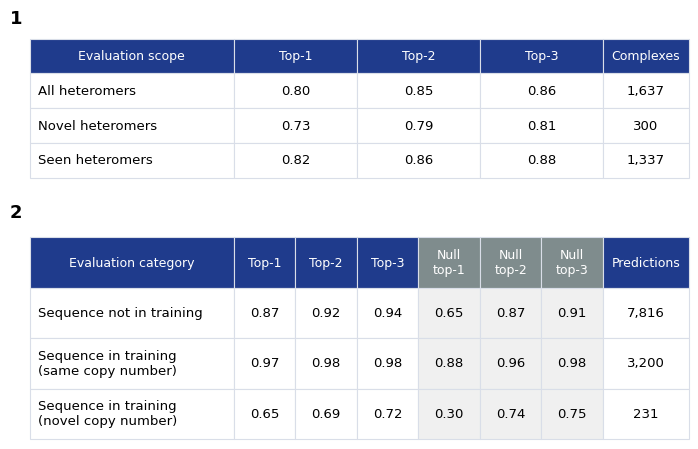

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

plt.rcParams["pdf.fonttype"] = 42

HEADER_BLUE = "#1f3b8c"
BASELINE_GREY = "#7f8c8d"
BASELINE_CELL = "#f0f0f0"
EDGE_COLOR = "#d9dee8"
BODY_FONT_SIZE = 9.5
FIRST_COLUMN_WIDTH = 0.31
LAST_COLUMN_WIDTH = 0.13
HEADER_FONT_SIZE = 9
OUTPUT_PDF_PATH = Path("thesis_figure/stoic_benchmark_tables.pdf")

complex_level_accuracy = pl.DataFrame(
    {
        "Evaluation scope": [
            "All heteromers",
            "Novel heteromers",
            "Seen heteromers",
        ],
        "Top-1": [0.80, 0.73, 0.82],
        "Top-2": [0.85, 0.79, 0.86],
        "Top-3": [0.86, 0.81, 0.88],
        "Complexes": [1637, 300, 1337],
    }
)

subunit_level_accuracy = pl.DataFrame(
    {
        "Evaluation category": [
            "Sequence not in training",
            "Sequence in training\n(same copy number)",
            "Sequence in training\n(novel copy number)",
        ],
        "Top-1": [0.87, 0.97, 0.65],
        "Top-2": [0.92, 0.98, 0.69],
        "Top-3": [0.94, 0.98, 0.72],
        "Null\ntop-1": [0.65, 0.88, 0.30],
        "Null\ntop-2": [0.87, 0.96, 0.74],
        "Null\ntop-3": [0.91, 0.98, 0.75],
        "Predictions": [7816, 3200, 231],
    }
)
null_model_columns = [name for name in subunit_level_accuracy.columns if name.startswith("Null")]
assert len(null_model_columns) == 3, "expected three null model columns"


def format_cell(value) -> str:
    if isinstance(value, float):
        return f"{value:.2f}"
    if isinstance(value, int):
        return f"{value:,}"
    return str(value)


def draw_table(axis, table_frame, header_colors, column_widths, cell_colors=None):
    assert len(header_colors) == table_frame.width, "one header color per column"
    assert len(column_widths) == table_frame.width, "one width per column"
    assert abs(sum(column_widths) - 1) < 1e-9, "column widths must sum to 1 so both tables align"
    cell_text = [[format_cell(value) for value in row] for row in table_frame.iter_rows()]
    axis.axis("off")
    table_handle = axis.table(
        cellText=cell_text,
        colLabels=table_frame.columns,
        colWidths=column_widths,
        cellLoc="center",
        loc="upper center",
        bbox=[0, 0, 1, 1],
    )
    table_handle.auto_set_font_size(False)
    table_handle.set_fontsize(BODY_FONT_SIZE)
    for (row_index, column_index), cell in table_handle.get_celld().items():
        cell.set_edgecolor(EDGE_COLOR)
        cell.set_linewidth(0.8)
        if row_index == 0:
            cell.set_facecolor(header_colors[column_index])
            cell.get_text().set_color("white")
            cell.get_text().set_fontsize(HEADER_FONT_SIZE)
            continue
        data_row = row_index - 1
        if cell_colors is not None:
            cell.set_facecolor(cell_colors[data_row][column_index])
        if column_index == 0:
            cell.get_text().set_horizontalalignment("left")
            cell.PAD = 0.04
    return table_handle


figure, (axis_complex, axis_subunit) = plt.subplots(
    2, 1, figsize=(8.5, 5.2), gridspec_kw={"height_ratios": [1, 1.45], "hspace": 0.35}
)

middle_column_space = 1 - FIRST_COLUMN_WIDTH - LAST_COLUMN_WIDTH

draw_table(
    axis_complex,
    complex_level_accuracy,
    header_colors=[HEADER_BLUE] * complex_level_accuracy.width,
    column_widths=[FIRST_COLUMN_WIDTH] + [middle_column_space / 3] * 3 + [LAST_COLUMN_WIDTH],
)

subunit_cell_colors = [
    [BASELINE_CELL if column_name in null_model_columns else "white" for column_name in subunit_level_accuracy.columns]
    for _ in range(subunit_level_accuracy.height)
]
subunit_header_colors = [
    BASELINE_GREY if column_name in null_model_columns else HEADER_BLUE
    for column_name in subunit_level_accuracy.columns
]
draw_table(
    axis_subunit,
    subunit_level_accuracy,
    header_colors=subunit_header_colors,
    column_widths=[FIRST_COLUMN_WIDTH] + [middle_column_space / 6] * 6 + [LAST_COLUMN_WIDTH],
    cell_colors=subunit_cell_colors,
)

for axis, panel_letter in [(axis_complex, "1"), (axis_subunit, "2")]:
    axis.text(-0.03, 1.08, panel_letter, transform=axis.transAxes, fontsize=13, fontweight="bold", va="bottom")

assert OUTPUT_PDF_PATH.parent.is_dir(), f"output folder {OUTPUT_PDF_PATH.parent} does not exist"
figure.savefig(OUTPUT_PDF_PATH, bbox_inches="tight")

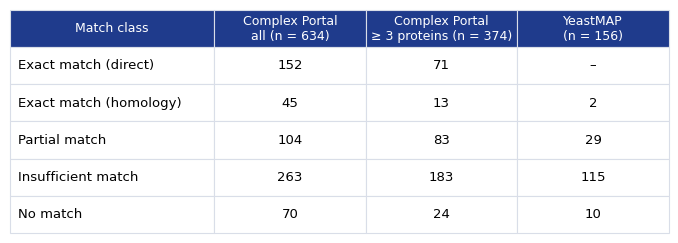

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

plt.rcParams["pdf.fonttype"] = 42

HEADER_BLUE = "#1f3b8c"
EDGE_COLOR = "#d9dee8"
BODY_FONT_SIZE = 9.5
HEADER_FONT_SIZE = 9
OUTPUT_PDF_PATH = Path("thesis_figure/pdb_matching_table.pdf")

match_class_counts = pl.DataFrame(
    {
        "Match class": [
            "Exact match (direct)",
            "Exact match (homology)",
            "Partial match",
            "Insufficient match",
            "No match",
        ],
        "Complex Portal\nall (n = 634)": [152, 45, 104, 263, 70],
        "Complex Portal\n≥ 3 proteins (n = 374)": [71, 13, 83, 183, 24],
        "YeastMAP\n(n = 156)": [None, 2, 29, 115, 10],
    }
)
expected_column_totals = {
    "Complex Portal\nall (n = 634)": 634,
    "Complex Portal\n≥ 3 proteins (n = 374)": 374,
    "YeastMAP\n(n = 156)": 156,
}
for column_name, expected_total in expected_column_totals.items():
    observed_total = match_class_counts[column_name].sum()
    assert observed_total == expected_total, f"{column_name} sums to {observed_total}, expected {expected_total}"


def format_cell(value) -> str:
    if value is None:
        return "–"
    if isinstance(value, int):
        return f"{value:,}"
    return str(value)


def draw_table(axis, table_frame, column_widths):
    assert len(column_widths) == table_frame.width, "one width per column"
    assert abs(sum(column_widths) - 1) < 1e-9, "column widths must sum to 1"
    cell_text = [[format_cell(value) for value in row] for row in table_frame.iter_rows()]
    axis.axis("off")
    table_handle = axis.table(
        cellText=cell_text,
        colLabels=table_frame.columns,
        colWidths=column_widths,
        cellLoc="center",
        loc="upper center",
        bbox=[0, 0, 1, 1],
    )
    table_handle.auto_set_font_size(False)
    table_handle.set_fontsize(BODY_FONT_SIZE)
    for (row_index, column_index), cell in table_handle.get_celld().items():
        cell.set_edgecolor(EDGE_COLOR)
        cell.set_linewidth(0.8)
        if row_index == 0:
            cell.set_facecolor(HEADER_BLUE)
            cell.get_text().set_color("white")
            cell.get_text().set_fontsize(HEADER_FONT_SIZE)
            continue
        cell.set_facecolor("white")
        if column_index == 0:
            cell.get_text().set_horizontalalignment("left")
            cell.PAD = 0.04
    return table_handle


figure, axis_matching = plt.subplots(figsize=(8.5, 2.9))
draw_table(axis_matching, match_class_counts, column_widths=[0.31, 0.23, 0.23, 0.23])

assert OUTPUT_PDF_PATH.parent.is_dir(), f"output folder {OUTPUT_PDF_PATH.parent} does not exist"
figure.savefig(OUTPUT_PDF_PATH, bbox_inches="tight")

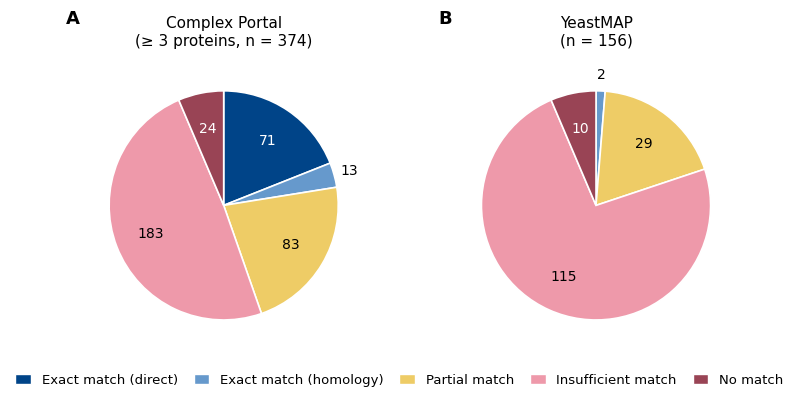

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.patches import Patch

plt.rcParams["pdf.fonttype"] = 42

FONT_SIZE = 10
MIN_FRACTION_FOR_INSIDE_LABEL = 0.06
OUTPUT_PDF_PATH = Path("thesis_figure/pdb_matching_pies.pdf")

match_class_colors = {
    "Exact match (direct)": "#004488",
    "Exact match (homology)": "#6699CC",
    "Partial match": "#EECC66",
    "Insufficient match": "#EE99AA",
    "No match": "#994455",
}
dark_wedges = {"Exact match (direct)", "No match"}

match_class_counts = pl.DataFrame(
    {
        "match_class": list(match_class_colors),
        "complex_portal_min3": [71, 13, 83, 183, 24],
        "yeastmap": [0, 2, 29, 115, 10],
    }
)
dataset_panels = [
    ("complex_portal_min3", "Complex Portal\n(≥ 3 proteins, n = 374)", 374),
    ("yeastmap", "YeastMAP\n(n = 156)", 156),
]
for column_name, _, expected_total in dataset_panels:
    observed_total = match_class_counts[column_name].sum()
    assert observed_total == expected_total, f"{column_name} sums to {observed_total}, expected {expected_total}"


def draw_match_pie(axis, class_names, class_counts, panel_title):
    nonzero_mask = class_counts > 0
    shown_names = [name for name, keep in zip(class_names, nonzero_mask) if keep]
    shown_counts = class_counts[nonzero_mask]
    wedges, _ = axis.pie(
        shown_counts,
        colors=[match_class_colors[name] for name in shown_names],
        startangle=90,
        counterclock=False,
        wedgeprops={"edgecolor": "white", "linewidth": 1.2},
    )
    total_count = shown_counts.sum()
    for wedge, class_name, count in zip(wedges, shown_names, shown_counts):
        fraction = count / total_count
        mid_angle = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
        if fraction >= MIN_FRACTION_FOR_INSIDE_LABEL:
            label_radius = 0.68
            text_color = "white" if class_name in dark_wedges else "black"
        else:
            label_radius = 1.14
            text_color = "black"
        axis.text(
            label_radius * np.cos(mid_angle),
            label_radius * np.sin(mid_angle),
            f"{count}",
            ha="center",
            va="center",
            fontsize=FONT_SIZE,
            color=text_color,
        )
    axis.set_title(panel_title, fontsize=FONT_SIZE + 1, pad=12)
    axis.set_aspect("equal")


figure, pie_axes = plt.subplots(1, 2, figsize=(8.5, 4.2))
for axis, (column_name, panel_title, _) in zip(pie_axes, dataset_panels):
    draw_match_pie(
        axis,
        match_class_counts["match_class"].to_list(),
        match_class_counts[column_name].to_numpy(),
        panel_title,
    )

for axis, panel_letter in zip(pie_axes, ["A", "B"]):
    axis.text(-0.05, 1.12, panel_letter, transform=axis.transAxes, fontsize=13, fontweight="bold", va="bottom")

legend_handles = [Patch(facecolor=color, edgecolor="white", label=name) for name, color in match_class_colors.items()]
figure.legend(handles=legend_handles, loc="lower center", ncol=5, frameon=False, fontsize=FONT_SIZE - 0.5,
              handlelength=1.2, columnspacing=1.2, bbox_to_anchor=(0.5, 0.04))
figure.subplots_adjust(bottom=0.12, wspace=0.3)

assert OUTPUT_PDF_PATH.parent.is_dir(), f"output folder {OUTPUT_PDF_PATH.parent} does not exist"
figure.savefig(OUTPUT_PDF_PATH, bbox_inches="tight")